<div style="background:linear-gradient(90deg,#f12711,#f5af19);padding:26px;border-radius:14px;color:white">
<h4 style="margin:0;opacity:0.9">🧬 AI GENESIS · THE STORY OF AI, ONE ALGORITHM AT A TIME</h4>
<h1 style="margin:6px 0 4px 0">Backpropagation (1986)</h1>
<p style="margin:0">The algorithm that finally taught <b>many-layer neural networks</b> how to learn.</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Year** | 1986 (popularized) |
| **Popularized by** | David Rumelhart, Geoffrey Hinton and Ronald Williams |
| **Earlier forms** | Seppo Linnainmaa (1970), Paul Werbos (1974) |
| **Family** | Neural models → the engine of Deep Learning |
| **Learns from data?** | ✅ Yes, using gradients |
| **Solves** | Training networks with **hidden layers** |
| **Builds on** | The Perceptron (1958) and the XOR problem |
| **Difficulty** | ⭐⭐⭐ Intermediate (we go slowly) |

### 🎯 What you will learn in this notebook
1. The story: why the Perceptron got stuck, and how this algorithm unstuck it
2. The idea of "passing the blame backwards"
3. The maths: forward pass, loss, chain rule, backward pass
4. **One full training step by hand** with real numbers
5. Build a neural network **from scratch** with only NumPy
6. **Check** that our gradients are correct (gradient checking)
7. Solve **XOR** (the problem the Perceptron could not) and look *inside* the hidden layer
8. Curved real-world-style data, hidden-layer size, and handwritten digits

## 📖 Part 1: The story

At the end of the last story, the Perceptron hit a wall: it could not solve **XOR**, and in 1969 Minsky and Papert pointed this out loudly. Funding and interest in neural networks cooled for years.

The fix was already clear in theory: **put neurons in layers**. A hidden layer can solve XOR (we did it by hand with McCulloch-Pitts neurons). But there was a missing piece:

> **How do you train the hidden neurons?** The Perceptron rule only knows the *final* error. Which hidden neuron is to blame for it? This is called the **credit assignment problem**.

### 💡 The answer: backpropagation
Use the **chain rule** from calculus to send the error **backwards** through the network, giving every weight its share of the blame.

- **1970**: Seppo Linnainmaa described the general method (reverse-mode automatic differentiation).
- **1974**: Paul Werbos proposed using it for neural networks in his PhD thesis.
- **1986**: Rumelhart, Hinton and Williams showed in *Nature* that it makes hidden layers learn useful internal representations. This paper made it famous.
- **1989**: Yann LeCun used it to train a network that read handwritten zip codes, and a theorem showed one hidden layer can approximate any smooth function given enough neurons (*universal approximation*).

Geoffrey Hinton shared the 2024 Nobel Prize in Physics for foundational work on neural networks.

### 🗺️ Where this fits
```
Perceptron (1958) → XOR wall (1969) → Backpropagation (1986) → CNNs / LSTM (1990s) → Deep Learning boom (2012) → Transformers (2017)
```

## 🧠 Part 2: The idea in plain words

Imagine a restaurant. A customer tastes the final dish and says **"too salty!"**

- The head chef knows the dish was wrong, and **by how much** (this is the *error*).
- The head chef asks each assistant chef: *"How much did your part contribute to the saltiness?"* An assistant who added a lot of a heavily used ingredient gets more blame.
- Each assistant adjusts their own recipe a little, and tells **their** helpers the same way.

That is backpropagation:

1. **Forward pass**: push the inputs through the network to get a prediction.
2. **Measure the error** (the loss).
3. **Backward pass**: send the error back, layer by layer, computing each weight's share of the blame (its *gradient*).
4. **Update**: nudge every weight a small step to reduce the error (*gradient descent*).
5. Repeat many times.

### ➗ The maths (for a network with one hidden layer)

**Forward pass**

$$z_1 = W_1 x + b_1 \qquad h = \sigma(z_1) \qquad z_2 = W_2 h + b_2 \qquad \hat{y} = \sigma(z_2)$$

where $\sigma(z) = \dfrac{1}{1+e^{-z}}$ is the **sigmoid**, a smooth version of the Perceptron's step function. Smoothness matters: we need *slopes* to know which way to nudge.

**Loss** (binary cross-entropy, small when the prediction is right and confident)

$$L = -\big[\,y \ln \hat{y} + (1-y)\ln(1-\hat{y})\,\big]$$

**Backward pass** (the chain rule, from output to input)

$$\delta_2 = \hat{y} - y \qquad\quad \frac{\partial L}{\partial W_2} = \delta_2\, h^{T} \qquad \frac{\partial L}{\partial b_2} = \delta_2$$

$$\delta_1 = (W_2^{T}\delta_2) \odot h \odot (1-h) \qquad\quad \frac{\partial L}{\partial W_1} = \delta_1\, x^{T} \qquad \frac{\partial L}{\partial b_1} = \delta_1$$

**Update** (η is the learning rate)

$$\theta \leftarrow \theta - \eta \,\frac{\partial L}{\partial \theta} \quad \text{for every weight and bias } \theta$$

> 🔎 Why is $\delta_2$ so simple? With a sigmoid output and cross-entropy loss, the sigmoid's slope cancels out neatly. And $h(1-h)$ in $\delta_1$ is just the slope of the sigmoid.

## 🟣 Step 1: Import the libraries
> 💡 Only `numpy` does the real work in our network. The others help with data, charts and comparison.

In [ ]:
# Import the libraries we need
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron as SkPerceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")      # keep the notebook output clean

# Styling and a colour palette used across the notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ORANGE, RED, BLUE, GREEN, PURPLE, GREY, DARK = "#f5af19", "#f12711", "#4776e6", "#27ae60", "#8e54e9", "#7f8c8d", "#2c3e50"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🖼️ Step 2: Picture the network and the two passes
> 💡 A tiny network: **2 inputs → 2 hidden neurons → 1 output**. 🟦 The **forward pass** goes left to right. 🟥 The **backward pass** sends the error right to left.

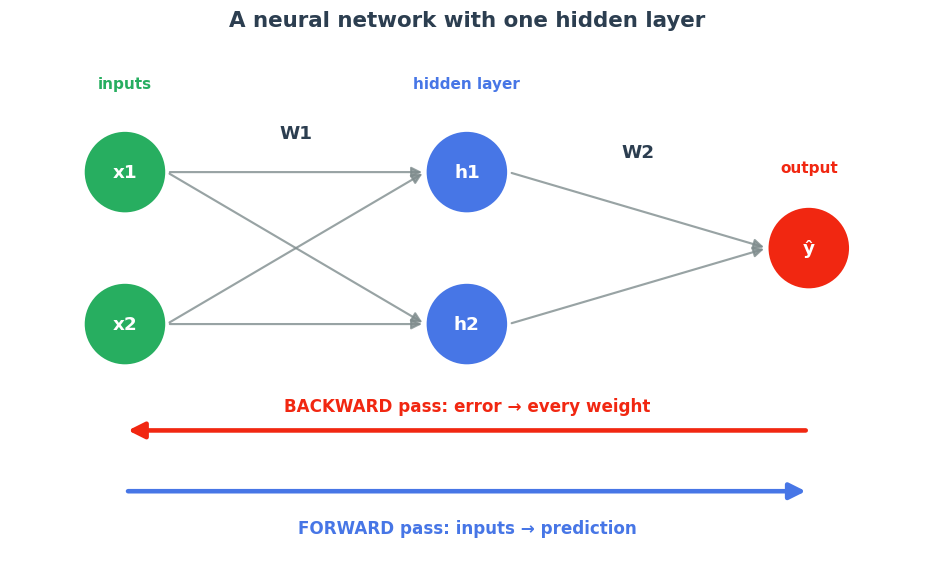

In [ ]:
# Draw a 2-2-1 network with the forward and backward passes
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 6.8); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("A neural network with one hidden layer", fontsize=14, color=DARK, fontweight="bold")

layers = {"input": [(1.5, 5.0), (1.5, 3.0)], "hidden": [(6.0, 5.0), (6.0, 3.0)], "output": [(10.5, 4.0)]}
cols = {"input": GREEN, "hidden": BLUE, "output": RED}
names = {"input": ["x1", "x2"], "hidden": ["h1", "h2"], "output": ["ŷ"]}

for a_name, b_name in [("input", "hidden"), ("hidden", "output")]:
    for (xa, ya) in layers[a_name]:
        for (xb, yb) in layers[b_name]:
            ax.add_patch(FancyArrowPatch((xa + 0.55, ya), (xb - 0.55, yb), arrowstyle="-|>", mutation_scale=14,
                                         color=GREY, lw=1.4, alpha=0.8))
for name, pts in layers.items():
    for (x, y), label in zip(pts, names[name]):
        ax.add_patch(Circle((x, y), 0.55, color=cols[name], ec="white", lw=2, zorder=3))
        ax.text(x, y, label, ha="center", va="center", color="white", fontweight="bold", fontsize=12, zorder=4)

ax.text(1.5, 6.1, "inputs", ha="center", color=GREEN, fontweight="bold")
ax.text(6.0, 6.1, "hidden layer", ha="center", color=BLUE, fontweight="bold")
ax.text(10.5, 5.0, "output", ha="center", color=RED, fontweight="bold")
ax.text(3.75, 5.45, "W1", color=DARK, fontsize=12, fontweight="bold", ha="center")
ax.text(8.25, 5.2, "W2", color=DARK, fontsize=12, fontweight="bold", ha="center")

ax.add_patch(FancyArrowPatch((10.5, 1.6), (1.5, 1.6), arrowstyle="-|>", mutation_scale=22, color=RED, lw=3))
ax.text(6.0, 1.85, "BACKWARD pass: error → every weight", ha="center", color=RED, fontsize=11, fontweight="bold")
ax.add_patch(FancyArrowPatch((1.5, 0.8), (10.5, 0.8), arrowstyle="-|>", mutation_scale=22, color=BLUE, lw=3))
ax.text(6.0, 0.25, "FORWARD pass: inputs → prediction", ha="center", color=BLUE, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## 📈 Step 3: The sigmoid and its slope
> 💡 The sigmoid squeezes any number into `(0, 1)`. Its **slope** (derivative) is `σ(z) · (1 − σ(z))`. It is largest in the middle (0.25) and nearly flat at both ends.
> Remember this: the flat ends will cause trouble later ("vanishing gradients").

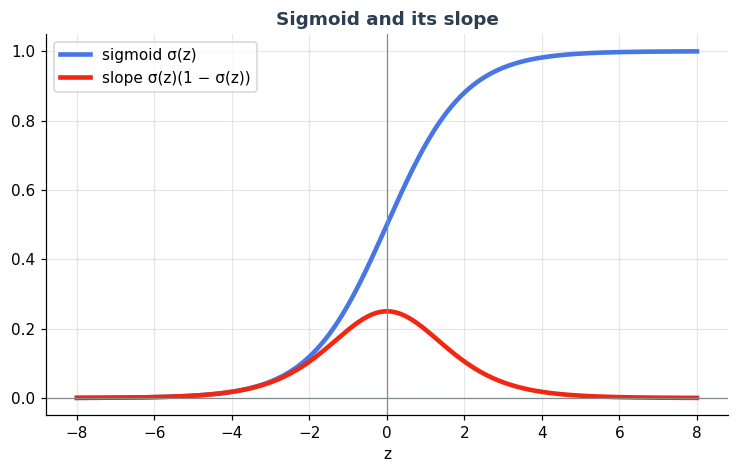

In [ ]:
# Plot the sigmoid and its derivative
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 300)
s = sigmoid(z)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(z, s, color=BLUE, lw=3, label="sigmoid σ(z)")
ax.plot(z, s * (1 - s), color=RED, lw=3, label="slope σ(z)(1 − σ(z))")
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ax.set_xlabel("z"); ax.set_title("Sigmoid and its slope", color=DARK, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## ✍️ Step 4: One full training step, by hand
> 💡 A tiny network with chosen starting weights, **one** example (`x = [1, 0]`, correct answer `y = 1`), and learning rate `0.5`.
> We do the forward pass, the loss, the backward pass, and the update, printing every number. Then we check that the new prediction is **better**.

In [ ]:
# One training step with explicit numbers
x = np.array([1.0, 0.0])
y_true = 1.0
lr = 0.5

W1 = np.array([[0.4, -0.3],      # weights of hidden neuron 1
               [0.2,  0.5]])     # weights of hidden neuron 2
b1 = np.array([0.1, -0.1])
W2 = np.array([[0.6, -0.5]])     # output neuron weights
b2 = np.array([0.2])

def forward_pass(W1, b1, W2, b2):
    z1 = W1 @ x + b1
    h = sigmoid(z1)
    z2 = W2 @ h + b2
    y_hat = sigmoid(z2)[0]
    loss = -(y_true * np.log(y_hat) + (1 - y_true) * np.log(1 - y_hat))
    return z1, h, z2, y_hat, loss

# ---- 1. forward pass ----
z1, h, z2, y_hat, loss = forward_pass(W1, b1, W2, b2)

# ---- 2. backward pass (chain rule) ----
delta2 = y_hat - y_true                       # error at the output
dW2 = delta2 * h.reshape(1, -1)               # gradient for W2
db2 = np.array([delta2])
delta1 = (W2.T[:, 0] * delta2) * h * (1 - h)  # blame passed back to the hidden neurons
dW1 = np.outer(delta1, x)                     # gradient for W1
db1 = delta1

# ---- 3. update every weight a little ----
W1n, b1n, W2n, b2n = W1 - lr * dW1, b1 - lr * db1, W2 - lr * dW2, b2 - lr * db2
_, _, _, y_hat_new, loss_new = forward_pass(W1n, b1n, W2n, b2n)

summary = pd.DataFrame({
    "quantity": ["hidden inputs z1", "hidden outputs h", "output input z2", "prediction ŷ", "loss",
                 "δ2 (output error)", "δ1 (hidden blame)", "gradient W2", "gradient W1"],
    "value": [np.round(z1, 4), np.round(h, 4), np.round(z2, 4), round(y_hat, 4), round(loss, 4),
              np.round(delta2, 4), np.round(delta1, 4), np.round(dW2, 4).tolist(), np.round(dW1, 4).tolist()]
})
print(summary.to_string(index=False))
print(f"\nBefore the update: prediction = {y_hat:.4f}, loss = {loss:.4f}")
print(f"After the update:  prediction = {y_hat_new:.4f}, loss = {loss_new:.4f}   (truth = 1)")
assert loss_new < loss
print("✅ One step made the network better!")

         quantity                            value
 hidden inputs z1                       [0.5, 0.1]
 hidden outputs h                  [0.6225, 0.525]
  output input z2                          [0.311]
     prediction ŷ                           0.5771
             loss                           0.5497
δ2 (output error)                          -0.4229
δ1 (hidden blame)                [-0.0596, 0.0527]
      gradient W2              [[-0.2632, -0.222]]
      gradient W1 [[-0.0596, -0.0], [0.0527, 0.0]]

Before the update: prediction = 0.5771, loss = 0.5497
After the update:  prediction = 0.6633, loss = 0.4106   (truth = 1)
✅ One step made the network better!


## 🤖 Step 5: Build the full neural network from scratch
> 💡 The same maths, but for **many examples at once** (matrices instead of single numbers). The class has:
> - `forward`: the forward pass
> - `backward`: the backward pass, which returns the gradients
> - `fit`: repeat *forward → backward → update* many times (full-batch gradient descent)
>
> Every line matches a formula from Part 2.

In [ ]:
# A neural network with one hidden layer, trained with backpropagation
class NeuralNetwork:
    '''Input -> hidden layer (sigmoid) -> output (sigmoid), trained with backpropagation.'''

    def __init__(self, sizes=(2, 4, 1), seed=0):
        rng = np.random.default_rng(seed)
        n_in, n_hidden, n_out = sizes
        self.W1 = rng.normal(0, 1, (n_hidden, n_in))       # small random start (not all zeros!)
        self.b1 = np.zeros(n_hidden)
        self.W2 = rng.normal(0, 1, (n_out, n_hidden))
        self.b2 = np.zeros(n_out)

    def forward(self, X):
        self.Z1 = X @ self.W1.T + self.b1
        self.H = sigmoid(self.Z1)
        self.Z2 = self.H @ self.W2.T + self.b2
        self.Y = sigmoid(self.Z2)
        return self.Y

    def loss(self, X, y):
        p = np.clip(self.forward(X), 1e-12, 1 - 1e-12)
        y = np.asarray(y).reshape(-1, 1)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

    def backward(self, X, y):
        n = len(X)
        y = np.asarray(y).reshape(-1, 1)
        self.forward(X)
        d2 = (self.Y - y) / n                      # δ2 (averaged over the examples)
        d1 = (d2 @ self.W2) * self.H * (1 - self.H)  # δ1 = (W2ᵀ δ2) ⊙ h ⊙ (1−h)
        return {"W2": d2.T @ self.H, "b2": d2.sum(axis=0),
                "W1": d1.T @ X,        "b1": d1.sum(axis=0)}

    def fit(self, X, y, lr=1.0, epochs=3000):
        X = np.asarray(X, dtype=float)
        self.loss_history = []
        for _ in range(epochs):
            grads = self.backward(X, y)
            for name, g in grads.items():              # gradient descent update
                setattr(self, name, getattr(self, name) - lr * g)
            self.loss_history.append(self.loss(X, y))
        return self

    def predict_proba(self, X):
        return self.forward(np.asarray(X, dtype=float)).ravel()

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

print("✅ NeuralNetwork class created!")

✅ NeuralNetwork class created!


## 🔬 Step 6: Is our backpropagation correct? (gradient checking)
> 💡 Backprop is easy to get subtly wrong. There is a classic trick to **verify** it: estimate each gradient the slow way, by nudging the weight up and down a tiny bit and watching the loss change:
> `gradient ≈ (loss(w + ε) − loss(w − ε)) / (2ε)`.
> If our fast backward pass is right, both answers should match almost perfectly.

In [ ]:
# Compare backpropagation gradients with slow numerical gradients
X_xor = np.array(list(itertools.product([0.0, 1.0], repeat=2)))
y_xor = np.array([0, 1, 1, 0])

net = NeuralNetwork(sizes=(2, 3, 1), seed=1)
analytic = net.backward(X_xor, y_xor)
eps = 1e-5

rows = []
for name in ["W1", "b1", "W2", "b2"]:
    param = getattr(net, name)
    numeric = np.zeros_like(param)
    for idx in np.ndindex(*param.shape):
        original = param[idx]
        param[idx] = original + eps; loss_plus = net.loss(X_xor, y_xor)
        param[idx] = original - eps; loss_minus = net.loss(X_xor, y_xor)
        param[idx] = original
        numeric[idx] = (loss_plus - loss_minus) / (2 * eps)
    rows.append({"parameter": name, "largest difference": f"{np.max(np.abs(numeric - analytic[name])):.2e}"})

print(pd.DataFrame(rows).to_string(index=False))
print("\n✅ Differences are tiny, so our backpropagation is correct!")

parameter largest difference
       W1           7.47e-12
       b1           3.33e-12
       W2           5.23e-12
       b2           8.55e-13

✅ Differences are tiny, so our backpropagation is correct!


## 🎯 Step 7: Solve XOR, the problem the Perceptron could not
> 💡 Same four examples as before: `0,0→0` · `0,1→1` · `1,0→1` · `1,1→0`.
> We train for 3000 epochs with learning rate `2`, then look at the loss curve and the predictions.

In [ ]:
# Train the network on XOR
net_xor = NeuralNetwork(sizes=(2, 4, 1), seed=0).fit(X_xor, y_xor, lr=2.0, epochs=3000)

print(f"Loss at the start: {net_xor.loss_history[0]:.4f}")
print(f"Loss at the end:   {net_xor.loss_history[-1]:.4f}")

results = pd.DataFrame({"x1": X_xor[:, 0].astype(int), "x2": X_xor[:, 1].astype(int),
                        "XOR (truth)": y_xor,
                        "network says": np.round(net_xor.predict_proba(X_xor), 3),
                        "decision": net_xor.predict(X_xor)})
assert (results["decision"] == results["XOR (truth)"]).all()
print("✅ XOR solved by a neural network trained with backpropagation!")
results

Loss at the start: 0.6896
Loss at the end:   0.0012
✅ XOR solved by a neural network trained with backpropagation!


,x1,x2,XOR (truth),network says,decision
0,0,0,0,0.001,0
1,0,1,1,0.998,1
2,1,0,1,0.999,1
3,1,1,0,0.001,0


## 📉 Step 8: Watch the learning, and see the boundary
> 💡 **Left:** the loss falling as the network learns. **Right:** the network's answer everywhere in the plane (blue = near 0, red = near 1).
> A single Perceptron could only draw one straight line. Look at the **curved** boundary here.

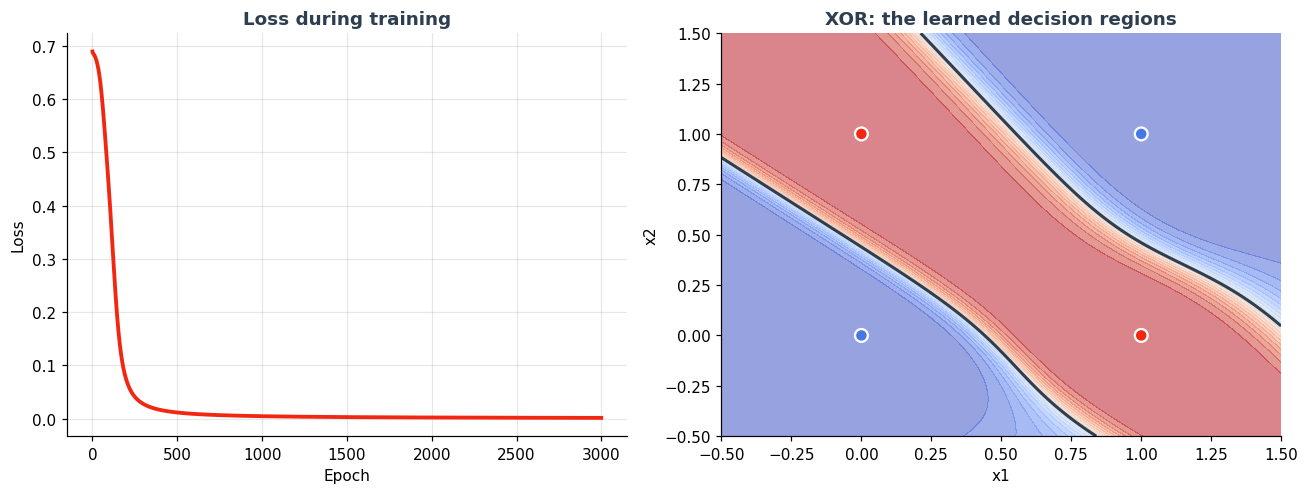

In [ ]:
# Helper: draw the decision regions of any model
def plot_regions(ax, predict_proba, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = predict_proba(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 21), cmap="coolwarm", alpha=0.55)
    ax.contour(xx, yy, zz, levels=[0.5], colors=DARK, linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(np.asarray(y) == 1, RED, BLUE), s=70, edgecolor="white", linewidth=1.5, zorder=3)
    ax.set_title(title, color=DARK, fontweight="bold")
    ax.set_xlabel("x1"); ax.set_ylabel("x2")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.plot(net_xor.loss_history, color=RED, lw=2.5)
ax1.set_title("Loss during training", color=DARK, fontweight="bold")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.grid(alpha=0.3)

plot_regions(ax2, net_xor.predict_proba, X_xor, y_xor, "XOR: the learned decision regions")
plt.tight_layout()
plt.show()

## 🔍 Step 9: What did the hidden layer learn?
> 💡 This is the real magic. The hidden layer **re-describes** the inputs in a new way, so that a problem which was impossible for one straight line becomes easy.
> We use a network with just **2 hidden neurons**, so the hidden layer is also a 2D picture.
> - **Left:** the original inputs (XOR, not separable by a line)
> - **Right:** the same four points after the hidden layer `(h1, h2)`. The two classes can now be split by a **single straight line**. (Notice that the two `1` points land on almost the same spot: the hidden layer *merged* them.)

✅ A 2-hidden-neuron network solved XOR (starting point #0)


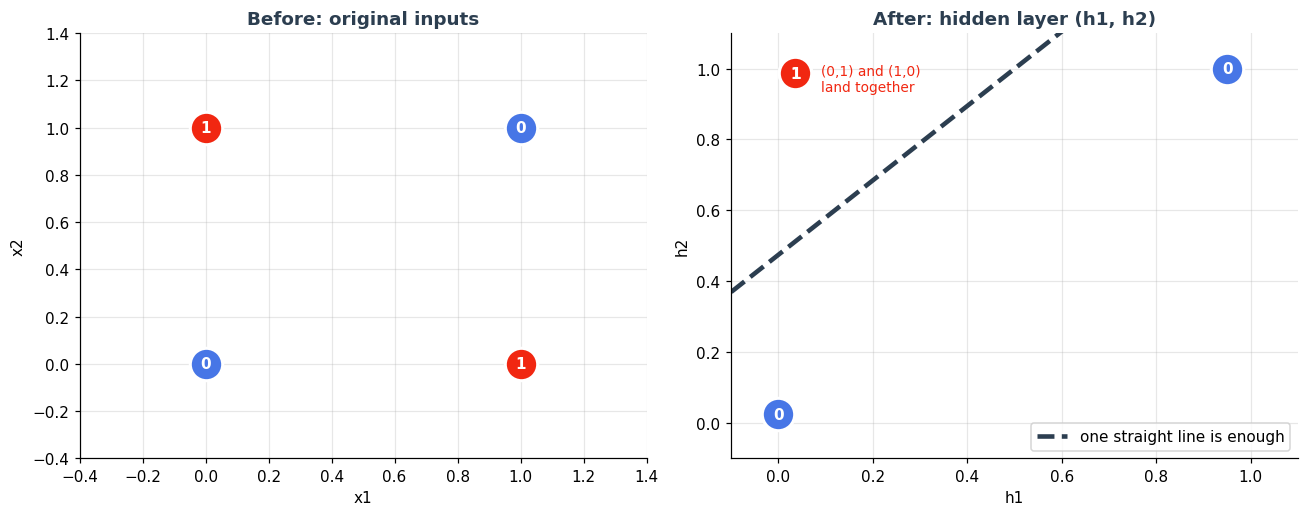

In [ ]:
# Train a very small network (2 hidden neurons) and look at the hidden representation
net_small = None
for seed in range(40):                                    # a few starting points may get stuck, so we try several
    candidate = NeuralNetwork(sizes=(2, 2, 1), seed=seed).fit(X_xor, y_xor, lr=3.0, epochs=4000)
    if (candidate.predict(X_xor) == y_xor).all():
        net_small, used_seed = candidate, seed
        break
print(f"✅ A 2-hidden-neuron network solved XOR (starting point #{used_seed})")

net_small.forward(X_xor)
hidden = net_small.H                                      # the points as seen by the output neuron

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, pts, title, xl, yl in [(ax1, X_xor, "Before: original inputs", "x1", "x2"),
                               (ax2, hidden, "After: hidden layer (h1, h2)", "h1", "h2")]:
    for point, t in zip(pts, y_xor):
        ax.scatter(point[0], point[1], s=450, color=RED if t else BLUE, edgecolor="white", linewidth=2, zorder=3)
        ax.text(point[0], point[1], str(t), ha="center", va="center", color="white", fontweight="bold", zorder=4)
    ax.set_title(title, color=DARK, fontweight="bold"); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(alpha=0.3)

# the output neuron's decision line in hidden space: w1*h1 + w2*h2 + b = 0
w_out, b_out = net_small.W2[0], net_small.b2[0]
hs = np.linspace(-0.1, 1.1, 50)
if abs(w_out[1]) > 1e-9:
    ax2.plot(hs, -(w_out[0] * hs + b_out) / w_out[1], color=DARK, lw=3, ls="--", label="one straight line is enough")
ax2.set_xlim(-0.1, 1.1); ax2.set_ylim(-0.1, 1.1); ax2.legend(loc="lower right")
ax2.text(0.09, 0.97, "(0,1) and (1,0)\nland together", color=RED, fontsize=9, va="center")
ax1.set_xlim(-0.4, 1.4); ax1.set_ylim(-0.4, 1.4)
plt.tight_layout()
plt.show()

## 🌙 Step 10: Curved data: single neuron vs neural network
> 💡 The *two moons* dataset has two interleaved crescents. No straight line can separate them. We compare:
> - scikit-learn's **Perceptron** (one neuron, straight line)
> - **our neural network** (16 hidden neurons, trained with backpropagation)

Single Perceptron (straight line) → test accuracy: 85.0%
Our neural network (hidden layer) → test accuracy: 93.3%


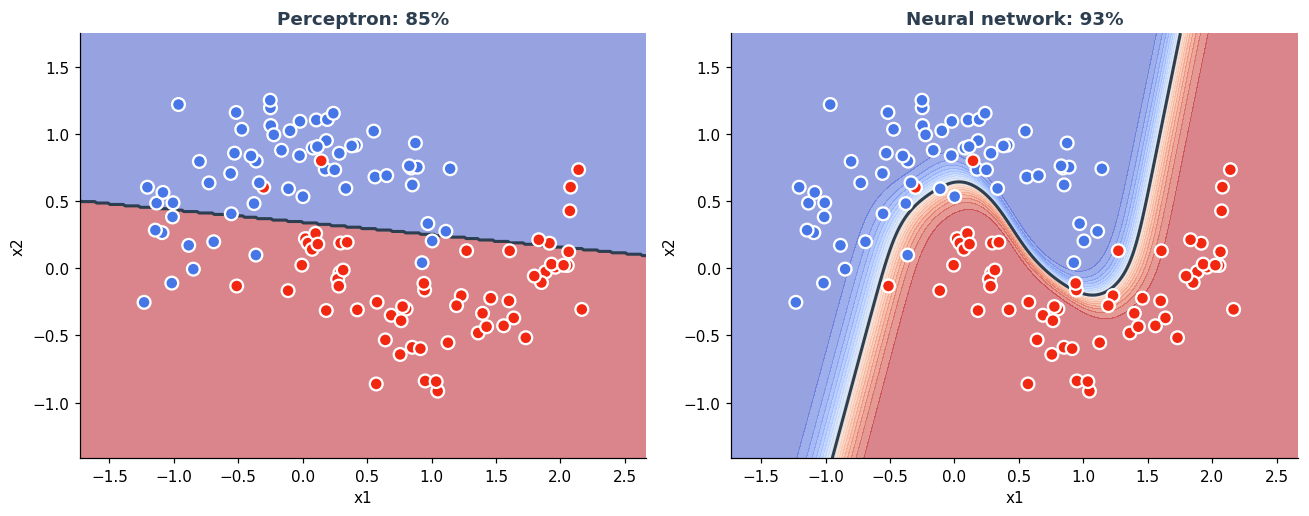

In [ ]:
# Create the moons data, split it, and train both models
X_m, y_m = make_moons(n_samples=400, noise=0.2, random_state=42)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_m, y_m, test_size=0.3, random_state=42, stratify=y_m)

single = SkPerceptron(random_state=42).fit(Xm_train, ym_train)
deep = NeuralNetwork(sizes=(2, 16, 1), seed=0).fit(Xm_train, ym_train, lr=1.0, epochs=4000)

acc_single = accuracy_score(ym_test, single.predict(Xm_test))
acc_deep = accuracy_score(ym_test, deep.predict(Xm_test))
print(f"Single Perceptron (straight line) → test accuracy: {acc_single:.1%}")
print(f"Our neural network (hidden layer) → test accuracy: {acc_deep:.1%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
plot_regions(ax1, lambda g: single.decision_function(g) > 0, Xm_test, ym_test, f"Perceptron: {acc_single:.0%}")
plot_regions(ax2, deep.predict_proba, Xm_test, ym_test, f"Neural network: {acc_deep:.0%}")
plt.tight_layout()
plt.show()

## 🧱 Step 11: Does the number of hidden neurons matter?
> 💡 We train the same network with 1, 2, 4, 8, 16 and 32 hidden neurons on the moons data and compare the **test accuracy**.
> Too few neurons cannot bend enough; more neurons give more flexibility.

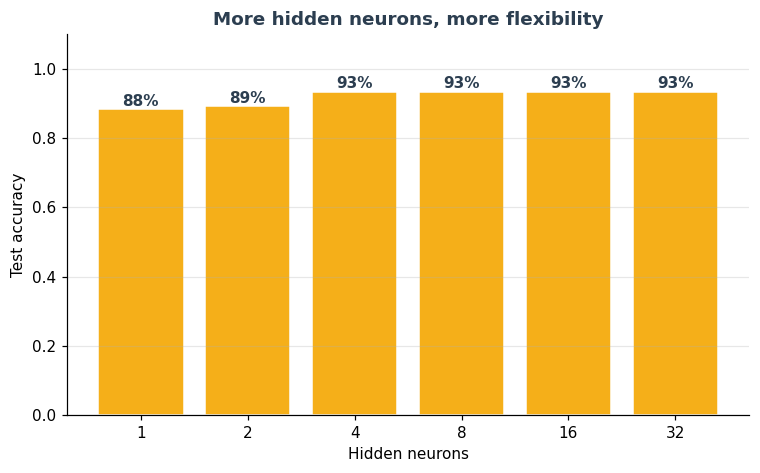

In [ ]:
# Try different hidden-layer sizes
sizes = [1, 2, 4, 8, 16, 32]
accs = []
for h in sizes:
    m = NeuralNetwork(sizes=(2, h, 1), seed=0).fit(Xm_train, ym_train, lr=1.0, epochs=3000)
    accs.append(accuracy_score(ym_test, m.predict(Xm_test)))

plt.figure(figsize=(8, 4.5))
bars = plt.bar([str(h) for h in sizes], accs, color=ORANGE, edgecolor="white")
for bar, a in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, a + 0.01, f"{a:.0%}", ha="center", fontweight="bold", color=DARK)
plt.ylim(0, 1.1)
plt.xlabel("Hidden neurons"); plt.ylabel("Test accuracy")
plt.title("More hidden neurons, more flexibility", color=DARK, fontweight="bold")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 🔢 Step 12: Real images: handwritten digits
> 💡 scikit-learn includes 1,797 small **8 × 8 images** of handwritten digits (0 to 9). We use the library's `MLPClassifier`, a multi-layer neural network trained with backpropagation, just like ours but optimized.
> Each image becomes 64 numbers (pixel brightness), scaled to `0..1`.

Test accuracy on 10 digit classes: 98.2%


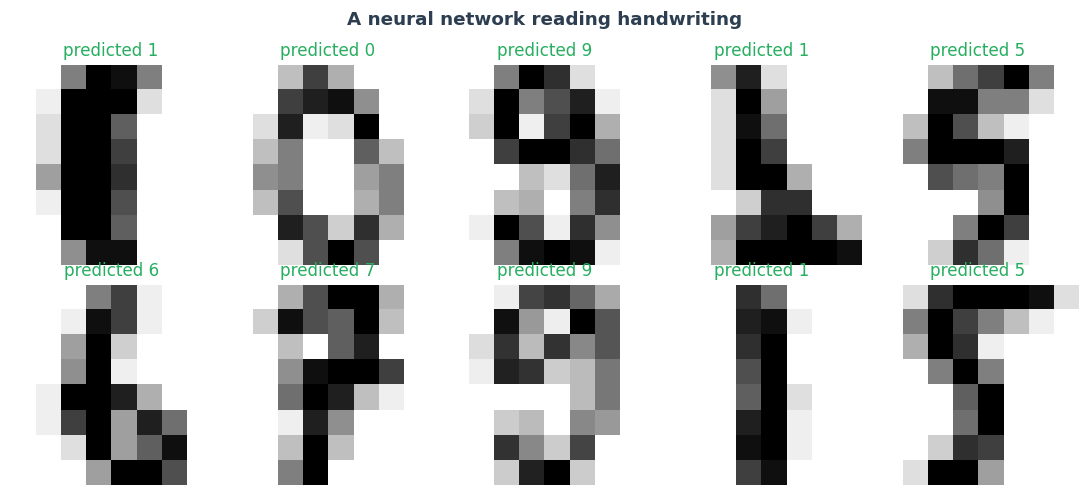

In [ ]:
# Train a neural network on handwritten digits
digits = load_digits()
X_d = digits.data / 16.0                         # pixel values 0..16 → 0..1
y_d = digits.target
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.25, random_state=42, stratify=y_d)

mlp = MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=42)
mlp.fit(Xd_train, yd_train)
pred = mlp.predict(Xd_test)
print(f"Test accuracy on 10 digit classes: {accuracy_score(yd_test, pred):.1%}")

# Show the first 10 test images with the prediction
fig, axes = plt.subplots(2, 5, figsize=(10, 4.6))
for ax, img, p, t in zip(axes.ravel(), Xd_test[:10], pred[:10], yd_test[:10]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"predicted {p}", color=GREEN if p == t else RED, fontsize=11)
    ax.axis("off")
plt.suptitle("A neural network reading handwriting", color=DARK, fontweight="bold")
plt.tight_layout()
plt.show()

## ⚠️ Limitations of backpropagation

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **Vanishing gradients** | The sigmoid's slope is tiny at its ends, so in deep networks the error signal fades away going backwards | ReLU activation, better initialization, batch normalization |
| ❌ **Local minima and plateaus** | Gradient descent can get stuck (we saw some XOR starts fail) | Momentum, Adam, many random restarts |
| ❌ **Hungry for data and compute** | Deep networks need lots of examples and fast hardware | GPUs and big datasets (2012 onwards) |
| ❌ **Sensitive to settings** | Learning rate, layer sizes and starting weights all matter | Careful tuning, adaptive optimizers |
| ❌ **A black box** | The weights are hard to interpret | Explainable AI research |

### 🧬 What it gave us
- A way to train networks of **any depth** by sharing the blame backwards
- The training engine behind **CNNs, RNNs, LSTMs and Transformers**
- The idea that hidden layers **learn their own features**

## 📝 Summary
1. ✅ Backpropagation solves the **credit assignment problem**: how much is each weight to blame for the error?
2. ✅ It uses the **chain rule** to pass the error backwards, layer by layer.
3. ✅ Then **gradient descent** nudges every weight to reduce the loss.
4. ✅ **Gradient checking** lets us prove our implementation is correct.
5. ✅ With a hidden layer, XOR and curved data become solvable, because the hidden layer **re-describes** the data.

## 🧪 Practice time
**Exercise 1.** Train the XOR network with **only 1 hidden neuron**. Can it reach 100% accuracy? Why or why not?

**Exercise 2.** Train the XOR network with a tiny learning rate (`lr=0.05`) for 3000 epochs. What happens to the loss? What does this tell you about the learning rate?

**Exercise 3.** Train a network on **3-input XOR** (output is 1 when an odd number of inputs are 1). Use 6 hidden neurons.

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1: one hidden neuron
best = 0
for seed in range(10):
    m = NeuralNetwork(sizes=(2, 1, 1), seed=seed).fit(X_xor, y_xor, lr=2.0, epochs=3000)
    best = max(best, accuracy_score(y_xor, m.predict(X_xor)))
print(best)   # never 1.0: one hidden neuron gives only one line, which is not enough for XOR

# Exercise 2: tiny learning rate
m = NeuralNetwork(sizes=(2, 4, 1), seed=0).fit(X_xor, y_xor, lr=0.05, epochs=3000)
print(m.loss_history[0], m.loss_history[-1])   # still far from 0 (compare with ~0.001 for lr=2): steps are too small, so learning is slow

# Exercise 3: 3-input XOR (parity)
X3 = np.array(list(itertools.product([0.0, 1.0], repeat=3)))
y3 = X3.sum(axis=1).astype(int) % 2
for seed in range(20):
    m = NeuralNetwork(sizes=(3, 6, 1), seed=seed).fit(X3, y3, lr=2.0, epochs=6000)
    if (m.predict(X3) == y3).all():
        print("solved with seed", seed)
        break
```
</details>

## ⏭️ What's next in AI-Genesis
The story continues: from small networks to **deep networks** with special shapes for images and sequences. 🚀